# Part 1C: Embedding Visualization

**Candidate Name:** Matteo Antony Mistretta

**Date:** 2026-10-17

**Environment:** Python 3.14, scikit-learn 1.9, umap-learn, pandas (exact versions in `requirements.txt`). Random seed fixed to 42.

*Visualize embedding space and analyze category separation*

## Overview

**What an embedding is.** The API turned each anchor into a list of 768 numbers, an *embedding*, saved in `embeddings/anchor.npy` (Part 1B). Each list can be seen as a point, or an arrow from the origin, in a 768-dimensional space. The model was trained so that texts with similar meaning get arrows pointing in similar directions, measured with **cosine similarity** (1 = same direction, 0 = unrelated; explained in Part 1B, Section 6).

**Goal of this section.** Part 2 will train a classifier on these embeddings, so before that I need to know how well the 9 categories are already separated in this space: which ones form clear groups, which ones overlap, and which points sit in the "wrong" neighbourhood. This predicts where the classifier will succeed and fail.

**Plan:**
1. **Look**: project the 768 dimensions down to 2 to draw maps of the space (three methods, since each distorts differently).
2. **Measure**: 2D maps can mislead, so I verify what they suggest with metrics computed in the full 768 dimensions.
3. **Inspect outliers**: points whose neighbours all belong to other categories.
4. **Matryoshka check**: test the README's claim that the embeddings can be shortened to fewer dimensions without losing quality.

### Setup

**What:** import the libraries, load the data and the embeddings, and keep **one point per distinct (anchor, category) pair**.

**Why one point per distinct pair:** Part 1A showed that 19% of rows repeat an anchor. Repeated anchors have identical embeddings, so plotting every row would draw the same point several times and give the small, heavily repeated categories (Demographic, Cost) extra weight in every metric. The 6 anchors with two different categories (Part 1A) are kept once per category.

**Libraries used here:** `scikit-learn` (already used in Parts 1A and 1B) provides PCA, t-SNE, the silhouette score and the nearest-neighbour search. Two are new in this part: `umap`, which provides UMAP, and `Counter` (from Python's standard library), which counts the categories among a point's neighbours. The seed makes the projections, which involve randomness, identical on every run.

In [1]:
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import umap
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_samples
from sklearn.neighbors import NearestNeighbors

SEED = 42
sns.set_theme(style="whitegrid", context="notebook")
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
pd.set_option("display.max_colwidth", 80)

df = pd.read_csv("data/endpoints_data.csv")
CATEGORIES = df["case"].value_counts().index.tolist()          # most frequent first
palette = dict(zip(CATEGORIES, sns.color_palette("tab10", len(CATEGORIES))))

emb_all = np.load("embeddings/anchor.npy")
norms = np.linalg.norm(emb_all, axis=1)
print(f"Embeddings: {emb_all.shape} | vector lengths: min {norms.min():.4f}, max {norms.max():.4f}")

uniq = df.drop_duplicates(["anchor", "case"]).copy()
E = emb_all[uniq.index.to_numpy()]                              # one embedding per distinct (anchor, category)
y = uniq["case"].to_numpy()                                     # its category
print(f"Distinct (anchor, category) points: {len(uniq)}")
print(f"Largest category among them: {pd.Series(y).value_counts().index[0]} "
      f"({pd.Series(y).value_counts(normalize=True).iloc[0]:.1%} of points)")

Embeddings: (3413, 768) | vector lengths: min 1.0000, max 1.0000
Distinct (anchor, category) points: 2767
Largest category among them: General Case (29.5% of points)


All vectors have length 1.0000: the API normalises them (`"normalize": true`), so the cosine similarity of two embeddings is simply their dot product. 2,767 distinct points remain. The largest category, General Case, holds 29.5% of them, which is the accuracy of a "classifier" that always answers General Case: the baseline any real model must beat.

## 1. Three 2D maps of the embedding space

**What:** project the 768-dimensional points onto a 2D plane and colour them by category.

**Why three methods:** squeezing 768 dimensions into 2 always loses information, like flattening the globe onto a map. Each method keeps something different:
- **PCA** (*principal component analysis*) is a **linear** projection: it finds the 2 directions along which the points vary the most and draws the points' shadow on that plane. It preserves global structure faithfully but can only show what fits in 2 straight directions. It also reports how much of the total variation those 2 directions capture.
- **t-SNE** and **UMAP** are **non-linear**: they move the points around so that each point's *nearest neighbours* stay close on the map. They reveal local groups much better, but distances *between* far-apart groups, and the size of groups, are not meaningful.

**Parameters:** all three use the cosine measure where applicable; t-SNE's *perplexity* (30) and UMAP's *neighbours* (15) set roughly how many neighbours each point tries to keep close. These are the libraries' standard defaults. UMAP runs on a single CPU core (`n_jobs=1`): in parallel its result would vary slightly between runs, even with a fixed seed.

PCA: the first 2 directions capture 15.4% of the total variation; the first 50 capture 88.3%


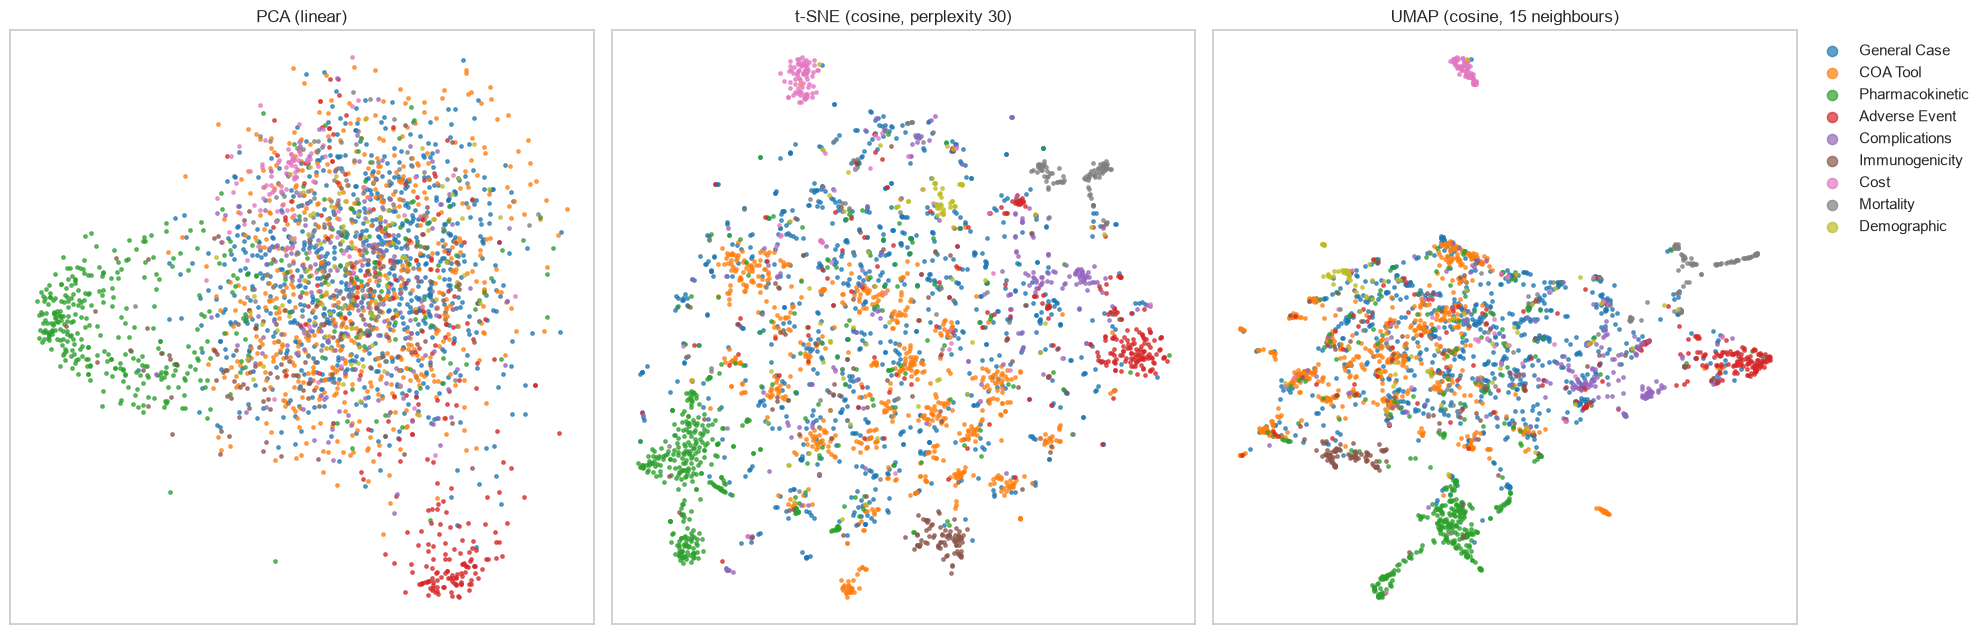

In [2]:
pca = PCA(n_components=50, random_state=SEED).fit(E)
cum = np.cumsum(pca.explained_variance_ratio_)
print(f"PCA: the first 2 directions capture {cum[1]:.1%} of the total variation; the first 50 capture {cum[49]:.1%}")

proj = {
    "PCA (linear)": pca.transform(E)[:, :2],
    "t-SNE (cosine, perplexity 30)": TSNE(n_components=2, metric="cosine", perplexity=30, init="pca",
                                          random_state=SEED).fit_transform(E),
    "UMAP (cosine, 15 neighbours)": umap.UMAP(n_neighbors=15, min_dist=0.1, metric="cosine",
                                              random_state=SEED, n_jobs=1).fit_transform(E),
}

fig, axes = plt.subplots(1, 3, figsize=(20, 6.5))
for ax, (name, P) in zip(axes, proj.items()):
    for c in CATEGORIES:
        m = y == c
        ax.scatter(P[m, 0], P[m, 1], s=6, alpha=0.7, color=palette[c], label=c)
    ax.set(title=name, xticks=[], yticks=[])
axes[2].legend(markerscale=3, bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)
plt.tight_layout(); plt.savefig(FIG_DIR / "1c_projections.png", dpi=120); plt.show()

**What:** with 9 colours on one map, overlapping categories are hard to see, so I redraw the UMAP map 9 times, highlighting one category at a time against all the others in grey.

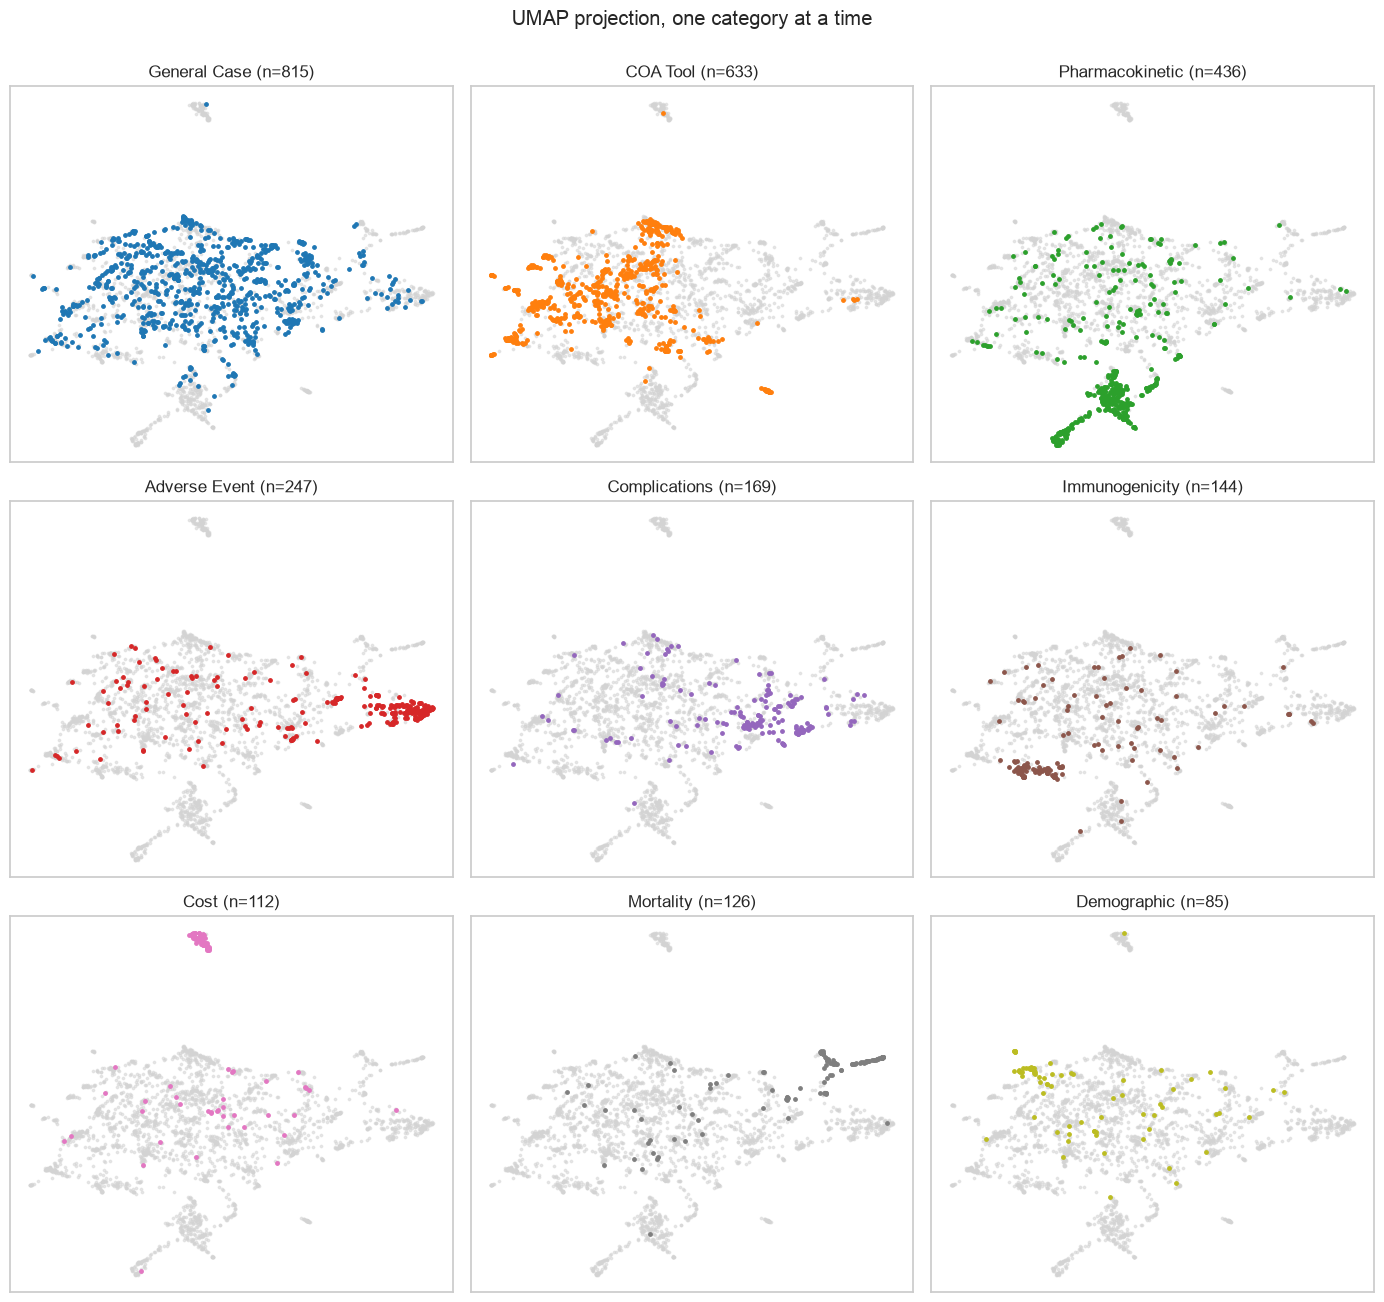

In [3]:
P = proj["UMAP (cosine, 15 neighbours)"]
fig, axes = plt.subplots(3, 3, figsize=(14, 13))
for ax, c in zip(axes.flat, CATEGORIES):
    m = y == c
    ax.scatter(P[~m, 0], P[~m, 1], s=3, color="lightgrey", alpha=0.5)
    ax.scatter(P[m, 0], P[m, 1], s=6, color=palette[c])
    ax.set(title=f"{c} (n={m.sum()})", xticks=[], yticks=[])
plt.suptitle("UMAP projection, one category at a time", y=1.0)
plt.tight_layout(); plt.savefig(FIG_DIR / "1c_umap_per_category.png", dpi=120); plt.show()

**Observations - maps**
- **PCA shows little structure**: its 2 directions capture only 15.4% of the total variation, and 50 directions are needed for 88.3% (first output above). The information is spread over many dimensions, so a linear 2D view understates how separated the categories are. Only **Pharmacokinetic** (green, left) and **Adverse Event** (red, bottom right) stand out: they are the most distinct "directions" in the space.
- **t-SNE and UMAP agree on the picture**: most smaller categories have a **tight core** away from the rest (on the UMAP map: Cost at the top, Mortality top right, Adverse Event on the right, Immunogenicity bottom left, Pharmacokinetic at the bottom) **plus a share of members scattered inside a large central mass**.
- That central mass is made of **General Case** and **COA Tool** (one-category maps). General Case spreads over the whole centre with no core of its own, consistent with it being a catch-all (Part 1A). COA Tool forms **many small tight islands** rather than one group; a plausible reading is that each island is one instrument with its variants and abbreviations, since the triplets pair names like *"FKSI-DRS"* with their full form (Part 1A).
- **Complications** has only a loose group between the central mass and Adverse Event; **Demographic** has a small group at the top left and the rest scattered.
- **Expectation for Part 2:** points in the cores should be classified easily; errors should concentrate on the scattered members, mostly confused with General Case and COA Tool.

## 2. Measuring separation in the full 768 dimensions

**Why:** the maps suggest a pattern, but they distort distances. These metrics are computed on the original embeddings, so they confirm or correct what the maps show. Each answers a different question:

- **Centroid similarity** — *are the categories' "average meanings" different?* A category's **centroid** is the average of its points, its centre of gravity. I compute the cosine similarity between every pair of centroids; close to 1 means the two categories are centred in the same place.
- **Cohesion** — *are points closer to their own centre than to another category's?* For each point: cosine similarity to its own centroid, versus to the nearest other centroid.
- **Silhouette** — *is each point inside its group or on a border?* A standard score from −1 to +1 that compares a point's average distance to its own category with its average distance to the nearest other category: **+1** = well inside its own group, **0** = on a border, **negative** = closer to another group.
- **kNN purity** — *who are each point's neighbours?* For each point I take its **10 nearest neighbours** (*k-nearest neighbours*, kNN, k = 10) and measure the share with the same category. I also let them **vote**: the most common category among the 10 is a prediction, and its accuracy is what a very simple classifier would get. The point itself is excluded from its own neighbours.

In [4]:
centroids = np.stack([E[y == c].mean(axis=0) for c in CATEGORIES])
centroids_n = centroids / np.linalg.norm(centroids, axis=1, keepdims=True)
cent_sim = pd.DataFrame(centroids_n @ centroids_n.T, index=CATEGORIES, columns=CATEGORIES)

sims_to_cent = E @ centroids_n.T                          # cosine similarity of each point to each centroid
sil = silhouette_samples(E, y, metric="cosine")
_, idx = NearestNeighbors(n_neighbors=11, metric="cosine").fit(E).kneighbors(E)
neighbour_labels = y[idx[:, 1:]]                          # column 0 is the point itself: skip it
knn_purity = (neighbour_labels == y[:, None]).mean(axis=1)
knn_vote = np.array([Counter(row).most_common(1)[0][0] for row in neighbour_labels])

rows = []
for i, c in enumerate(CATEGORIES):
    m = y == c
    other = np.delete(sims_to_cent[m], i, axis=1)
    rows.append({
        "category": c, "n": m.sum(),
        "sim_to_own_centroid": sims_to_cent[m, i].mean(),
        "sim_to_nearest_other": other.max(axis=1).mean(),
        "nearest_other_category": np.delete(np.array(CATEGORIES), i)[other.mean(axis=0).argmax()],
        "silhouette": sil[m].mean(),
        "knn10_purity": knn_purity[m].mean(),
        "knn10_vote_acc": (knn_vote[m] == c).mean(),
    })
metrics = pd.DataFrame(rows).set_index("category").sort_values("knn10_purity", ascending=False)
print(f"Overall: silhouette {sil.mean():.3f} | kNN-10 purity {knn_purity.mean():.3f} | "
      f"kNN-10 vote accuracy {(knn_vote == y).mean():.3f}")
metrics.round(3)

Overall: silhouette 0.006 | kNN-10 purity 0.594 | kNN-10 vote accuracy 0.704


,n,sim_to_own_centroid,sim_to_nearest_other,nearest_other_category,silhouette,knn10_purity,knn10_vote_acc
category,,,,,,,
COA Tool,633,0.177,0.273,General Case,-0.108,0.767,0.937
Pharmacokinetic,436,0.580,0.380,COA Tool,0.199,0.736,0.743
Cost,112,0.627,0.299,Pharmacokinetic,0.282,0.701,0.732
Adverse Event,247,0.510,0.310,General Case,0.157,0.648,0.688
Mortality,126,0.362,0.237,Pharmacokinetic,0.016,0.647,0.714
Immunogenicity,144,0.538,0.391,General Case,0.120,0.599,0.639
Complications,169,0.404,0.348,General Case,-0.002,0.450,0.556
General Case,815,0.182,0.291,COA Tool,-0.112,0.399,0.571
Demographic,85,0.343,0.218,General Case,0.001,0.360,0.459


**What:** two charts of the metrics above.

**Left: heatmap of centroid similarities.** Each cell is the cosine similarity between the centres of two categories.
- **How to read it:** off the diagonal, **darker (purple) = more distinct centres = better** for classification; **brighter (green/yellow) = the two centres nearly coincide**, a warning sign. The diagonal is always 1.00 (a category compared with itself) and can be ignored.
- **Caveat:** a centre is only an *average*. A category made of many separate small groups can have its average land in the middle of other categories even if each small group is well separated, so a bright cell means "these may overlap, check further", not a verdict.

**Right: violin plot of silhouette scores.** One "violin" per category.
- **Horizontal position** is the silhouette score of a point, from −1 to +1. **Right of the dashed 0 line** = the point is closer to its own category than to the nearest other one; **left of 0** = it is closer to another category.
- **Thickness** at a position shows how many points have that score (a histogram, smoothed and mirrored). The three dashed lines inside split the points into quarters; the middle one is the median.
- **What good looks like:** most of the body right of 0 (a well-separated category). **Two bulges** (*bimodal*), one right of 0 and one around or left of it, mean a tight core plus scattered members. A body **entirely left of 0** means the category has no group of its own.

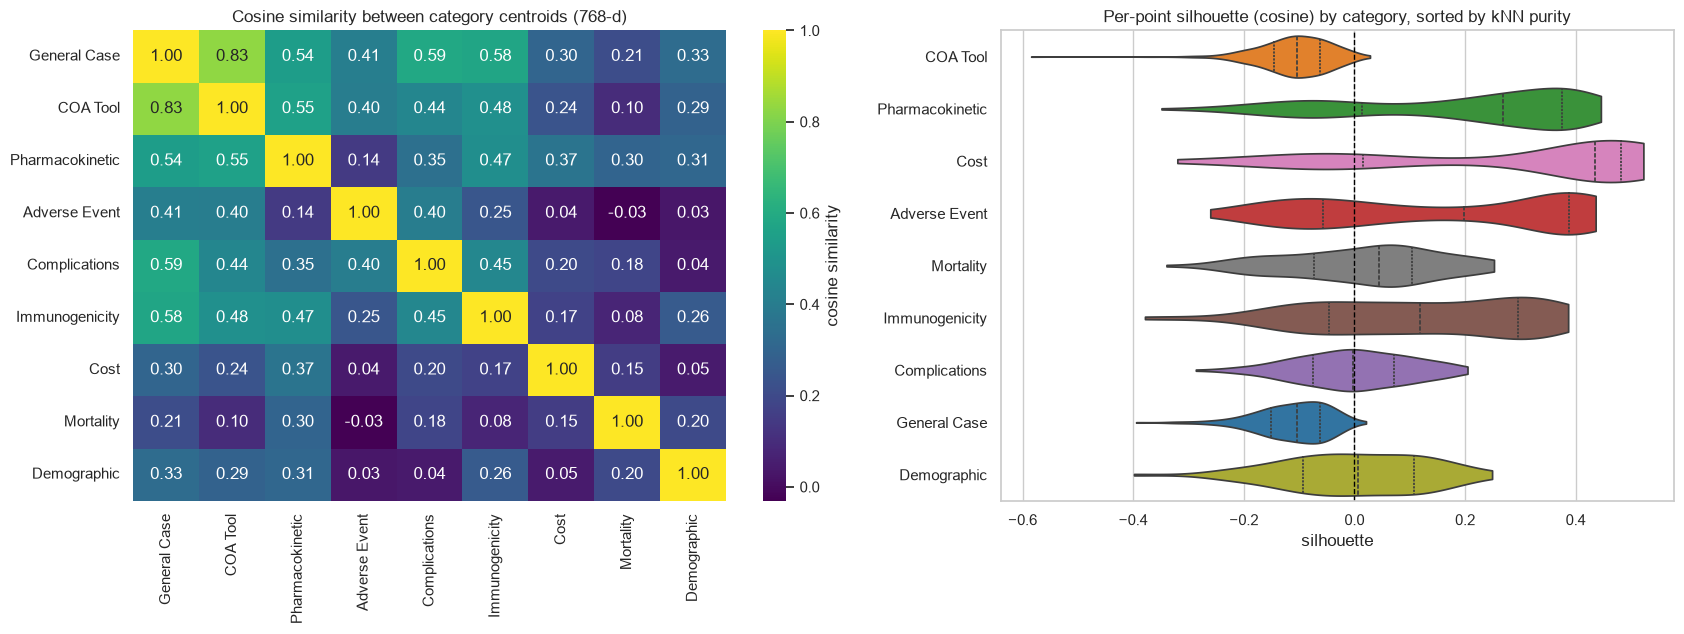

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={"width_ratios": [1.1, 1]})
sns.heatmap(cent_sim, annot=True, fmt=".2f", cmap="viridis", ax=axes[0], cbar_kws={"label": "cosine similarity"})
axes[0].set(title="Cosine similarity between category centroids (768-d)")

plot_df = pd.DataFrame({"category": y, "silhouette": sil})
sns.violinplot(data=plot_df, y="category", x="silhouette", order=metrics.index.tolist(), ax=axes[1],
               palette=palette, hue="category", legend=False, cut=0, inner="quartile")
axes[1].axvline(0, color="black", lw=1, ls="--")
axes[1].set(title="Per-point silhouette (cosine) by category, sorted by kNN purity", ylabel="")
plt.tight_layout(); plt.savefig(FIG_DIR / "1c_separation_metrics.png", dpi=120); plt.show()

**What:** for each category, which categories its points' 10 nearest neighbours belong to.

**Why:** kNN purity says *how often* a category's neighbourhoods are mixed; this table says *with which categories*, i.e. the likely confusions in Part 2.

**How to read it:** row = a point's category, column = its neighbours' category, value = % of neighbours. **Careful: the reading is the opposite of the centroid heatmap.** Here darker = *more* neighbours from that category, so **a dark diagonal is good** (neighbours from the same category; the diagonal is the kNN purity), while **a dark cell off the diagonal is the warning**: it shows where a category's neighbourhoods "leak", i.e. the likely confusions in Part 2.

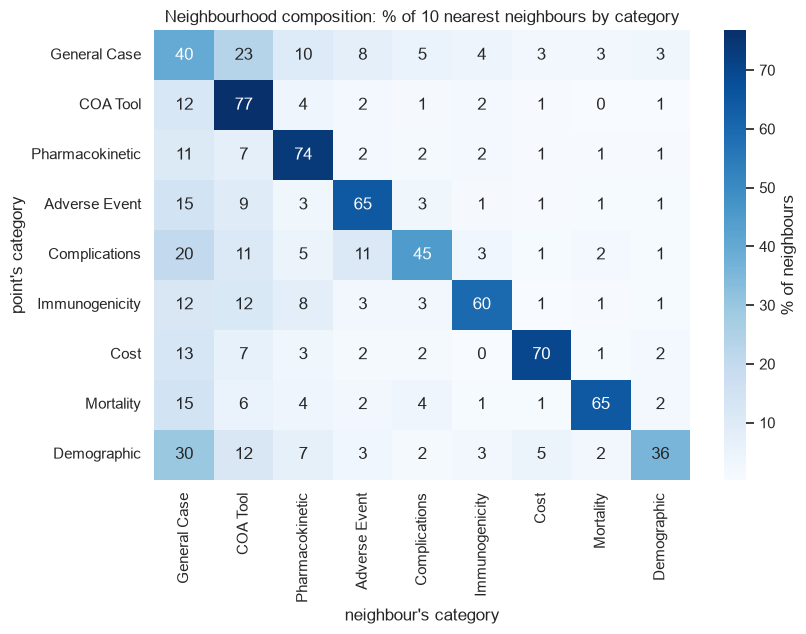

In [6]:
leak = (pd.crosstab(np.repeat(y, 10), neighbour_labels.ravel(), normalize="index")
          .reindex(index=CATEGORIES, columns=CATEGORIES))
fig, ax = plt.subplots(figsize=(8.5, 6.5))
sns.heatmap(leak * 100, annot=True, fmt=".0f", cmap="Blues", ax=ax, cbar_kws={"label": "% of neighbours"})
ax.set(title="Neighbourhood composition: % of 10 nearest neighbours by category",
       xlabel="neighbour's category", ylabel="point's category")
plt.tight_layout(); plt.savefig(FIG_DIR / "1c_knn_neighbourhood.png", dpi=120); plt.show()

**Observations - separation in 768 dimensions**
- **Weak global grouping, strong local structure.** The overall silhouette is **0.006**, essentially 0: categories are not compact, well-separated blobs. Yet simply letting the 10 nearest neighbours vote already gives **70.4% accuracy** (first output of Section 2), versus 11% for random guessing among 9 categories and 29.5% for always answering General Case (Setup). This fits how the embedding model was trained: triplets taught it to put texts with *similar meaning* close together (Part 1A, domain background), not to gather each *category* into one compact group.
- **COA Tool is the clearest case** (metrics table): it has the lowest similarity to its own centroid (0.177) and a negative silhouette (−0.108), yet the **highest kNN purity (0.767) and 93.7% vote accuracy**. It is many small islands, not one group: centroid-based measures miss this, neighbour-based ones capture it. For classification, **neighbourhoods are the better guide**.
- This also answers the Part 1A token question: **COA Tool and Pharmacokinetic, two of the three categories with the most fragmented words (45% and 38% of anchors, Part 1A), have the highest kNN purity** (0.767 and 0.736); the third, Immunogenicity (40%), is mid-ranked (0.599). Fragmented acronyms and names do not stop the fine-tuned model from grouping texts well.
- **Centroids** (left heatmap): the General Case and COA Tool centres are almost the same (**0.83**). Both categories are spread over the same central region, so each one's average is close to the average of "everything". General Case is also close to Complications (0.59) and Immunogenicity (0.58). Mortality, Demographic and Cost have the most isolated centres: their highest similarity to any other centre is 0.30, 0.33 and 0.37 respectively.
- **Two-bulge silhouettes** (violin plot) for Pharmacokinetic, Cost and Adverse Event confirm the "core + scattered members" pattern from the maps: one group of points well above 0, another around or below it.
- **Neighbourhoods leak mostly into General Case** (last heatmap): it makes up 30% of Demographic's neighbours, 20% of Complications', and 15% of Adverse Event's and Mortality's. The other notable leaks are General Case → COA Tool (23%) and **Complications → Adverse Event (11%)**, the pair with the most shared vocabulary in Part 1A.
- **Expected difficulty**, by kNN purity: easiest COA Tool, Pharmacokinetic, Cost; then Adverse Event, Mortality, Immunogenicity; hardest **Complications (0.450), General Case (0.399) and Demographic (0.360)**.

## 3. Outliers

**What:** list the points with **no** neighbour of their own category among their 10 nearest, together with the category their neighbours voted for.

**Why:** these are the points a classifier based on these embeddings will almost certainly get wrong. Reading them shows *why*: a wrong label, a genuinely ambiguous endpoint, or a weakness of the embeddings. I also compare how many of them come from real rows, to test the Part 1A finding that label noise originates in real anchors.

**How:** the table is sorted by silhouette, most "misplaced" first. `is_synthetic` refers to the first row in which the anchor appears.

In [7]:
uniq_eval = uniq.assign(knn_purity=knn_purity, knn_vote=knn_vote, silhouette=sil)
outliers = uniq_eval[uniq_eval["knn_purity"] == 0].sort_values("silhouette")
print(f"Points with no same-category neighbour among their 10 nearest: {len(outliers)} of {len(uniq_eval)} "
      f"({len(outliers) / len(uniq_eval):.1%})")
print(f"Share from real (non-synthetic) rows: {(~outliers['is_synthetic']).mean():.0%} among outliers, "
      f"{(~uniq_eval['is_synthetic']).mean():.0%} among all points")
outliers[["anchor", "case", "knn_vote", "is_synthetic", "silhouette"]].head(15)

Points with no same-category neighbour among their 10 nearest: 275 of 2767 (9.9%)
Share from real (non-synthetic) rows: 12% among outliers, 13% among all points


,anchor,case,knn_vote,is_synthetic,silhouette
2285,COmprehensive Score for financial Toxicity,COA Tool,Cost,True,-0.584548
264,household income,Demographic,Cost,True,-0.398561
777,symptoms of local anaesthetic toxicity,General Case,Adverse Event,True,-0.394767
330,ocular side-effects,General Case,Adverse Event,True,-0.393117
1135,Avalglucosidase Alfa,Immunogenicity,Pharmacokinetic,True,-0.378779
907,Nadir serum asparaginase activity (NSAA) levels,General Case,Pharmacokinetic,True,-0.367069
232,Minimization of Safety Hazards,Pharmacokinetic,Adverse Event,True,-0.348906
1537,belantamab maf,Immunogenicity,Pharmacokinetic,True,-0.342624
3026,Death\nRate of Cardiovascular and all-cause death,Mortality,Pharmacokinetic,True,-0.339893
2602,plasma anti-ovalbumin IgG levels,General Case,Immunogenicity,True,-0.336022


**Observations - outliers**
- **275 points (9.9%)** have no same-category neighbour among their 10 nearest (output above). Any classifier built on these embeddings will very likely get them wrong.
- Reading the table, they fall into recognisable groups:
  - **Endpoints that genuinely belong to two categories**: *"COmprehensive Score for financial Toxicity"* is a questionnaire (COA Tool) *about* costs, and its neighbours are Cost; *"household income"* (Demographic) sits among Cost. The embedding is arguably right; a single label is the limitation.
  - **Inconsistent labels**: *"ocular side-effects"* and *"symptoms of local anaesthetic toxicity"* are labelled General Case but sit among Adverse Events, where their meaning belongs. *"ocular side-effects"* is one of the 6 anchors with two different labels found in Part 1A.
  - **Drug and molecule names without context**: *"belantamab maf"* and *"Avalglucosidase Alfa"* (labelled Immunogenicity) sit among Pharmacokinetic, where most drug names are. As noted in Part 1A, a bare drug name does not say *what* is measured.
- Outliers are **not more often from real rows**: 12% among outliers vs 13% overall. Part 1A found that suspicious labels originate in real anchors, but those are few; the bulk of the hard cases comes from **ambiguous endpoints and blurry category boundaries**, which affect real and synthetic rows alike.

## 4. Matryoshka check: can the embeddings be shortened?

**What:** the README says the model has a **Matryoshka** property (named after the Russian nesting dolls): its first 512, 256, 128 or 64 numbers form a smaller embedding that still works, because training packed the most important information into the first dimensions. I keep only the first *d* numbers of each embedding, rescale the vectors to length 1 (as the API would), and recompute kNN purity, kNN vote accuracy and silhouette.

**Why:** if category information survives in fewer dimensions, the embeddings could be stored and compared 12x more cheaply (64 instead of 768 numbers), and a smaller input could reduce overfitting in Part 2.

In [8]:
rows = []
for d in [768, 512, 256, 128, 64]:
    Ed = E[:, :d] / np.linalg.norm(E[:, :d], axis=1, keepdims=True)
    _, ix = NearestNeighbors(n_neighbors=11, metric="cosine").fit(Ed).kneighbors(Ed)
    vote = np.array([Counter(r).most_common(1)[0][0] for r in y[ix[:, 1:]]])
    rows.append({"dim": d, "knn10_purity": (y[ix[:, 1:]] == y[:, None]).mean(),
                 "knn10_vote_acc": (vote == y).mean(),
                 "silhouette": silhouette_samples(Ed, y, metric="cosine").mean()})
pd.DataFrame(rows).set_index("dim").round(3)

,knn10_purity,knn10_vote_acc,silhouette
dim,,,
768,0.594,0.704,0.006
512,0.594,0.705,0.005
256,0.593,0.708,0.005
128,0.592,0.699,0.002
64,0.587,0.702,0.000


**Observations - Matryoshka**
- Quality is essentially **unchanged from 768 down to 64 dimensions** (table above): kNN vote accuracy stays at 0.70-0.71 and purity goes from 0.594 to 0.587. For this task, a 64-number embedding, 12x smaller, keeps nearly all the category information. The README's claim holds, and it would be a sensible choice for storage- or speed-sensitive production use. For Part 2 I will keep the full 768 dimensions, since there is no reason to discard information at this data size.

## Part 1C Summary
- **The embedding space has strong local structure but weak global grouping** (Sections 1-2): categories appear as tight cores plus members scattered in a central mass of General Case and COA Tool. A 10-nearest-neighbours vote already reaches **70.4%** accuracy, far above the 29.5% baseline, even though the silhouette is ~0.
- **Neighbour-based measures predict difficulty better than centroid-based ones** (Section 2), so a classifier that can draw flexible, non-linear boundaries (Part 2's neural network) should beat both this kNN vote and a linear model.
- **Expected hardest categories: Demographic, General Case and Complications**, with errors flowing mostly *into* General Case; easiest: COA Tool, Pharmacokinetic and Cost (Section 2).
- **About 10% of points have no same-category neighbour** (Section 3): mostly genuinely ambiguous endpoints or inconsistent labels, a ceiling on achievable accuracy rather than a model failure.
- **The embeddings can be truncated to 64 dimensions** with no measurable loss for this task (Section 4).